In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error ,r2_score

In [2]:
df = pd.read_csv('uber.csv')

In [3]:
# preprocessing
df.info

<bound method DataFrame.info of         Unnamed: 0                            key  fare_amount  \
0         24238194    2015-05-07 19:52:06.0000003          7.5   
1         27835199    2009-07-17 20:04:56.0000002          7.7   
2         44984355   2009-08-24 21:45:00.00000061         12.9   
3         25894730    2009-06-26 08:22:21.0000001          5.3   
4         17610152  2014-08-28 17:47:00.000000188         16.0   
...            ...                            ...          ...   
199995    42598914   2012-10-28 10:49:00.00000053          3.0   
199996    16382965    2014-03-14 01:09:00.0000008          7.5   
199997    27804658   2009-06-29 00:42:00.00000078         30.9   
199998    20259894    2015-05-20 14:56:25.0000004         14.5   
199999    11951496   2010-05-15 04:08:00.00000076         14.1   

                pickup_datetime  pickup_longitude  pickup_latitude  \
0       2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1       2009-07-17 20:04:56 UTC    

In [4]:
df.describe()

,Unnamed: 0,fare_amount,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
count,2.000000e+05,200000.000000,200000.000000,200000.000000,199999.000000,199999.000000,200000.000000
mean,2.771250e+07,11.359955,-72.527638,39.935885,-72.525292,39.923890,1.684535
std,1.601382e+07,9.901776,11.437787,7.720539,13.117408,6.794829,1.385997
min,1.000000e+00,-52.000000,-1340.648410,-74.015515,-3356.666300,-881.985513,0.000000
25%,1.382535e+07,6.000000,-73.992065,40.734796,-73.991407,40.733823,1.000000
50%,2.774550e+07,8.500000,-73.981823,40.752592,-73.980093,40.753042,1.000000
75%,4.155530e+07,12.500000,-73.967154,40.767158,-73.963658,40.768001,2.000000
max,5.542357e+07,499.000000,57.418457,1644.421482,1153.572603,872.697628,208.000000


In [5]:
df.head(5)

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [6]:
print(df.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [7]:
df = df.dropna()

In [8]:
print(df.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


In [9]:
df.dtypes

Unnamed: 0             int64
key                      str
fare_amount          float64
pickup_datetime          str
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

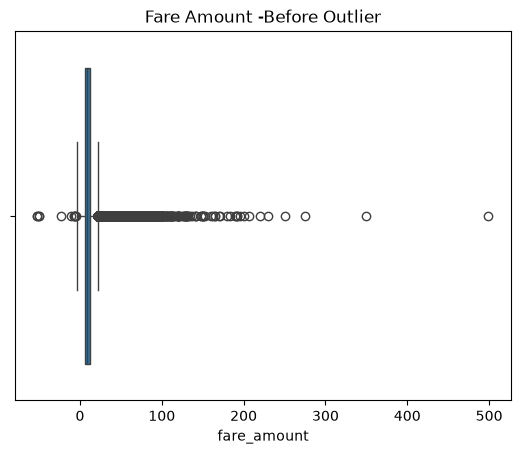

In [10]:
# removing outliers
sns.boxplot(x=df['fare_amount'])
plt.title("Fare Amount -Before Outlier")
plt.show()

In [11]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)
IQR = Q3-Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower limit:",lower , "Upper limit:",upper)
df = df[(df['fare_amount']>=lower) & (df['fare_amount'] <=upper)]

Lower limit: -3.75 Upper limit: 22.25


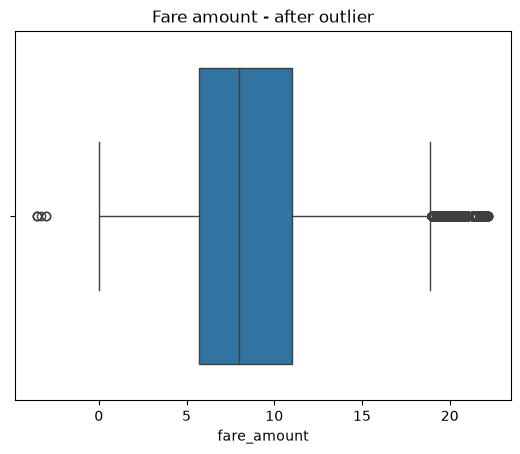

In [12]:
sns.boxplot(x = df['fare_amount'])
plt.title('Fare amount - after outlier')
plt.show()

In [13]:
#distance
dlat = df['dropoff_latitude'] - df['pickup_latitude']
dlong = df['dropoff_longitude'] - df['pickup_longitude']
df["distance"] = (dlat**2 + dlong**2) ** 0.5
    

In [14]:
#filtering
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] < 100)]
df = df[(df['passenger_count'] > 0) & (df['passenger_count'] <=6)]
df = df[df['distance'] < 5]

In [15]:
# extract time features
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

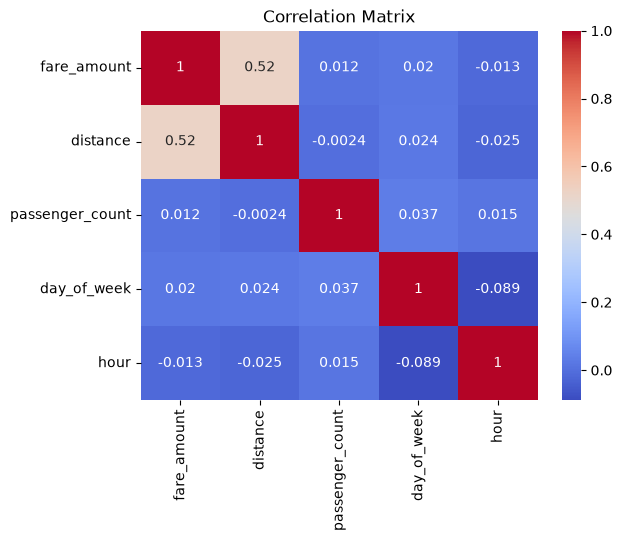

In [16]:
corr = df[['fare_amount','distance','passenger_count','day_of_week','hour']].corr()
sns.heatmap(corr , annot=True, cmap = 'coolwarm')
plt.title(" Correlation Matrix ")
plt.show()

In [17]:
X = df[['distance','passenger_count','hour','day_of_week']]
y = df['fare_amount']

In [25]:
X_train , X_test , y_train , y_test = train_test_split(
    X,y,test_size = 0.2 , random_state = 42)
lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred_lr =  lr.predict(X_test)



In [26]:
rf= RandomForestRegressor()
rf.fit(X_train,y_train)
y_pred_rf = rf.predict(X_test)

In [27]:
def evaluate(y_true ,y_pred,model_name):
    rmse = np.sqrt(mean_squared_error(y_true,y_pred))
    r2 =r2_score(y_true,y_pred)
    print(f"{model_name} Results:")
    print(f"R2 score: {r2:.6f}")
    print(f"RMSE: {rmse:.6f}\n")

    


In [28]:
evaluate(y_test,y_pred_lr,"Linear Regression")
evaluate(y_test,y_pred_rf,"RandomForest Regression")

Linear Regression Results:
R2 score: 0.265375
RMSE: 3.555552

RandomForest Regression Results:
R2 score: 0.637738
RMSE: 2.496811

